<a href="https://colab.research.google.com/github/2303880-Mandi/Bridging-Theory-and-Practice-in-Kernel-Based-Dequantization-of-VQML/blob/main/Cali_Housing_Prices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# California Housing: PQC vs KRR vs KTA-weighted KRR

Compares a trained re-uploading PQC, KRR with the uniform-weight PQC kernel, and KRR with a KTA-learned product-form re-weighted kernel ($d=5$, $L=5$). Predictions are reported as median house value in units of \$100k; the internal $[-1,1]$ scaling is inverted with `to_price`, which is clipped to the observed training price range, so negative prices cannot occur.

In [ ]:
!pip install pennylane -q

In [ ]:
import os, time, json, itertools
import numpy as np
import matplotlib
matplotlib.use("Agg") if os.environ.get("HEADLESS") else None
import matplotlib.pyplot as plt
import pennylane as qml
from pennylane import numpy as pnp
import autograd.numpy as anp
from autograd import grad
from scipy.optimize import minimize
from sklearn.kernel_ridge import KernelRidge

# colours: PQC = purple, KRR with uniform w = green, KRR with KTA-learned w = blue
PQC_COLOR     = "#7B2CBF"
KRR_COLOR     = "#1F5FD1"   # KRR with KTA-learned w
KRR_UNI_COLOR = "#2E9E4F"   # KRR with uniform w (green)
plt.rcParams.update({
    "font.size": 16, "axes.titlesize": 18, "axes.labelsize": 17,
    "xtick.labelsize": 15, "ytick.labelsize": 15,
    "legend.fontsize": 15, "legend.frameon": True, "legend.framealpha": 0.95, "legend.edgecolor": "0.3",
    "axes.linewidth": 1.4, "figure.dpi": 100,
})
os.makedirs("figures", exist_ok=True)

## 1. Configuration

In [ ]:
SEED = 0
D = 5                       # number of features = number of qubits
L = 5                       # R_X re-uploads per feature -> integer frequencies {-L..L}
FEATURES = ["MedInc", "HouseAge", "AveRooms", "Latitude", "Longitude"]

N_TRAIN, N_VAL, N_TEST = 2000, 1000, 2000
N_KTA = 1000                  # training points used to evaluate KTA (cost grows as N_KTA^2)
KTA_RESTARTS = 5
SWEEP = [100, 250, 500, 1000, 2000]                  # training-set sizes for the learning curve
SWEEP_RESTARTS = 2
LAMBDAS = [1e-12, 1e-10, 1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]

PQC_BLOCK_LAYERS = 1        # StronglyEntanglingLayers per trainable block
PQC_STEPS, PQC_BATCH, PQC_LR = 300, 100, 0.05

PREFIX = "housing"          # figure file prefix
assert len(FEATURES) == D
n_total = (2*L + 1)**D
print(f"Full spectrum: {n_total} frequencies; |Omega_D| = {(n_total - 1)//2 + 1}")

Full spectrum: 161051 frequencies; |Omega_D| = 80526


## 2. Data

Features are clipped to the training 1st-99th percentiles and rescaled to $[0,\pi]$. The target is rescaled to $[-1,1]$ to match the range of $\langle Z_0\rangle$. Scaling constants are fitted on the training split only. All plots show median house value in \$100k via `to_price` (affine map back, clipped to $[y_{min},y_{max}]$ of the training prices).

In [ ]:
from sklearn.datasets import fetch_california_housing
def load_raw():
    if os.environ.get("SYNTHETIC_SMOKE_TEST"):          # only used to test the code path offline
        r = np.random.default_rng(0); n = 6000
        X = np.column_stack([r.lognormal(1.2, .5, n), r.uniform(1, 52, n), r.lognormal(1.7, .3, n),
                             r.uniform(32.5, 42, n), r.uniform(-124, -114, n)])
        y = np.clip(0.4*X[:, 0] + 0.02*X[:, 1] + r.normal(0, .5, n), 0.15, 5.0)
        return X, y, ["MedInc", "HouseAge", "AveRooms", "Latitude", "Longitude"]
    data = fetch_california_housing(as_frame=False)
    return data.data, data.target, list(data.feature_names)

rng = np.random.default_rng(SEED)
X_all, y_all, names = load_raw()
cols = [names.index(f) for f in FEATURES]
X_all = X_all[:, cols]

assert N_TRAIN + N_VAL + N_TEST <= len(y_all)

perm = rng.permutation(len(y_all))
i_te = perm[:N_TEST]
i_va = perm[N_TEST:N_TEST + N_VAL]
i_tr = perm[N_TEST + N_VAL:N_TEST + N_VAL + N_TRAIN]

lo, hi = np.percentile(X_all[i_tr], [1, 99], axis=0)
def prep_X(X):
    return (np.clip(X, lo, hi) - lo) / (hi - lo) * np.pi        # -> [0, pi]

ymin, ymax = y_all[i_tr].min(), y_all[i_tr].max()
def prep_y(y):
    return 2 * (y - ymin) / (ymax - ymin) - 1                     # -> [-1, 1]

Xtr, Xva, Xte = prep_X(X_all[i_tr]), prep_X(X_all[i_va]), prep_X(X_all[i_te])
ytr, yva, yte = prep_y(y_all[i_tr]), prep_y(y_all[i_va]), prep_y(y_all[i_te])

rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b))**2)))
to_units = lambda r: r * (ymax - ymin) / 2                        # RMSE in scaled units -> target units
# scaled output in [-1, 1] -> median house value in target units.
# The map is affine onto [ymin, ymax] and then clipped, so predictions can never leave the observed
# training range (so no negative house prices).
to_price = lambda r: np.clip(ymin + (np.asarray(r, float) + 1) * (ymax - ymin) / 2, ymin, ymax)
print("train/val/test:", Xtr.shape, Xva.shape, Xte.shape)
print("target range in training data:", round(ymin, 3), "to", round(ymax, 3))
print("baseline RMSE (predict the training mean):",
      round(to_units(rmse(yte, ytr.mean())), 4), "x $100k")

train/val/test: (2000, 5) (1000, 5) (2000, 5)
target range in training data: 0.175 to 5.0
baseline RMSE (predict the training mean): 1.1724 x $100k


## 3. Product-structured PQC kernel

Each feature $j$ has a symmetric distribution over $\{-L,\dots,L\}$, parametrised by $L+1$ logits (softmax) over $|k|=0,\dots,L$. The full kernel is the element-wise product over features:
$$K_{(\mathcal{D},w)}(x,x')=\prod_{j=1}^{d}\sum_{k=-L}^{L}p_j(k)\cos\bigl(k(x_j-x_j')\bigr).$$

In [ ]:
def feat(xj, L):
    # xj: (n,) -> (n, 2L+1) = [1, cos(kx)_{k=1..L}, sin(kx)_{k=1..L}]
    kx = np.outer(xj, np.arange(1, L + 1))
    return np.hstack([np.ones((len(xj), 1)), np.cos(kx), np.sin(kx)])

def make_feats(X, L):
    return [feat(X[:, j], L) for j in range(X.shape[1])]

def weights_from_logits(lg):
    e = anp.exp(lg - anp.max(lg))
    u = e / anp.sum(e)                                   # u_0..u_L, sums to 1
    return anp.concatenate([u[:1], u[1:], u[1:]])

def gram(F1, F2, logits):
    K = 1.0
    for j in range(len(F1)):
        w = weights_from_logits(logits[j])
        K = K * ((F1[j] * w) @ F2[j].T)
    return K

# uniform p_j over {-L..L}: u_0 = 1/(2L+1), u_k = 2/(2L+1)  <=>  w = (1,...,1)
UNIFORM_LOGITS = np.tile(np.log(np.array([1.0] + [2.0] * L)), (D, 1))

# Sanity check: product formula == brute-force sum over the whole product spectrum (small case)
def brute_force_kernel(X1, X2, logits, L):
    Dd = logits.shape[0]
    ks = np.arange(-L, L + 1)
    P = []
    for j in range(Dd):
        u = np.exp(logits[j]); u = u / u.sum()
        p = np.empty(2*L + 1); p[L] = u[0]
        for k in range(1, L + 1):
            p[L + k] = p[L - k] = u[k] / 2
        P.append(p)
    K = np.zeros((len(X1), len(X2)))
    for idx in itertools.product(range(2*L + 1), repeat=Dd):
        om = ks[list(idx)]
        K += np.prod([P[j][idx[j]] for j in range(Dd)]) * np.cos((X1[:, None, :] - X2[None, :, :]) @ om)
    return K

r = np.random.default_rng(1)
Xa, Xb = r.uniform(0, np.pi, (20, 2)), r.uniform(0, np.pi, (15, 2))
lg = r.normal(size=(2, 3))
K_fast = gram(make_feats(Xa, 2), make_feats(Xb, 2), lg)
K_brute = brute_force_kernel(Xa, Xb, lg, 2)
print("max |product - brute force| =", np.abs(K_fast - K_brute).max())
assert np.abs(K_fast - K_brute).max() < 1e-12
print("diag(K) == 1:", np.allclose(np.diag(gram(make_feats(Xa, 2), make_feats(Xa, 2), lg)), 1.0))

max |product - brute force| = 5.551115123125783e-16
diag(K) == 1: True


## 4. Kernel ridge regression

In [ ]:
def krr_predict(Ktr, Kxt, y, lam):
    n = len(y)
    alpha = np.linalg.solve(Ktr + n * lam * np.eye(n), y)
    return np.clip(Kxt @ alpha, -1, 1)      # keep predictions inside the training target range

def eval_weights(logits, Ftr, ytr, Fva, yva, Fte, yte):
    Ktr, Kva, Kte = gram(Ftr, Ftr, logits), gram(Fva, Ftr, logits), gram(Fte, Ftr, logits)
    best = min(((rmse(krr_predict(Ktr, Kva, ytr, lam), yva), lam) for lam in LAMBDAS))
    pte = krr_predict(Ktr, Kte, ytr, best[1])
    return dict(lam=best[1], val_rmse=best[0], test_rmse=rmse(pte, yte), pred=pte)

def eval_rbf(Xtr, ytr, Xva, yva, Xte, yte):
    best = None
    for g in [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]:
        for a in LAMBDAS:
            m = KernelRidge(kernel="rbf", gamma=g, alpha=a * len(ytr)).fit(Xtr, ytr)
            r_ = rmse(np.clip(m.predict(Xva), -1, 1), yva)
            if best is None or r_ < best[0]:
                best = (r_, g, a, m)
    pte = np.clip(best[3].predict(Xte), -1, 1)
    return dict(gamma=best[1], lam=best[2], val_rmse=best[0], test_rmse=rmse(pte, yte), pred=pte)

## 5. Kernel target alignment

Centred alignment maximised over the product-weight logits with exact autograd gradients and L-BFGS-B, with random restarts.

In [ ]:
def centered(K):
    return K - anp.mean(K, axis=0, keepdims=True) - anp.mean(K, axis=1, keepdims=True) + anp.mean(K)

def alignment(logits, F, y):
    yc = y - y.mean()
    Y = np.outer(yc, yc)
    K = centered(gram(F, F, logits))
    return float(np.sum(K * Y) / (np.sqrt(np.sum(K * K)) * np.sqrt(np.sum(Y * Y))))

def learn_weights(F, y, restarts, seed=0, verbose=True):
    Dd, Lp1 = len(F), F[0].shape[1] // 2 + 1
    yc = y - y.mean()
    Y = np.outer(yc, yc); Ynorm = np.sqrt(np.sum(Y * Y))
    def loss(flat):
        K = centered(gram(F, F, flat.reshape(Dd, Lp1)))
        return -anp.sum(K * Y) / (anp.sqrt(anp.sum(K * K)) * Ynorm)
    g = grad(loss)
    r = np.random.default_rng(seed)
    base = np.tile(np.log(np.array([1.0] + [2.0] * (Lp1 - 1))), (Dd, 1))
    runs = []
    for i in range(restarts):
        x0 = (base if i == 0 else base + r.normal(size=base.shape)).ravel()   # restart 0 = uniform start
        t0 = time.time()
        res = minimize(loss, x0, jac=g, method="L-BFGS-B",
                       bounds=[(-12, 12)] * x0.size, options={"maxiter": 200})
        runs.append((-res.fun, res.x.reshape(Dd, Lp1)))
        if verbose:
            print(f"  restart {i}: alignment {-res.fun:.4f}  ({time.time() - t0:.0f}s)")
    return sorted(runs, key=lambda t: -t[0])

## 6. The PQC

Five qubits, one per feature, each uploaded $L$ times with $R_X(x_j)$, interleaved with trainable `StronglyEntanglingLayers`; observable $Z_0$.

In [ ]:
dev = qml.device("default.qubit", wires=D)

@qml.qnode(dev, interface="autograd", diff_method="backprop")
def circuit(weights, x):
    # x has shape (batch, D); weights has shape (L+1, PQC_BLOCK_LAYERS, D, 3)
    for r in range(L):
        qml.StronglyEntanglingLayers(weights[r], wires=range(D))
        for j in range(D):
            qml.RX(x[:, j], wires=j)
    qml.StronglyEntanglingLayers(weights[L], wires=range(D))
    return qml.expval(qml.PauliZ(0))

def pqc_predict(w, X, chunk=500):
    return np.concatenate([np.asarray(circuit(w, X[i:i + chunk])) for i in range(0, len(X), chunk)])

def make_cost(xb, yb):
    # data are captured in a closure so that only the circuit weights are trainable
    return lambda w_: pnp.mean((circuit(w_, xb) - yb) ** 2)

pr = np.random.default_rng(SEED)
w = pnp.array(pr.uniform(0, 2*np.pi, size=(L + 1, PQC_BLOCK_LAYERS, D, 3)), requires_grad=True)
opt = qml.AdamOptimizer(stepsize=PQC_LR)

hist = []
t0 = time.time()
for step in range(PQC_STEPS):
    idx = pr.choice(len(ytr), size=min(PQC_BATCH, len(ytr)), replace=False)
    xb = pnp.array(Xtr[idx], requires_grad=False)
    yb = pnp.array(ytr[idx], requires_grad=False)
    w, c = opt.step_and_cost(make_cost(xb, yb), w)
    if step % max(1, PQC_STEPS // 10) == 0 or step == PQC_STEPS - 1:
        hist.append((step, rmse(pqc_predict(w, Xtr), ytr), rmse(pqc_predict(w, Xva), yva)))
        print(f"step {step:4d}  train RMSE {hist[-1][1]:.4f}  val RMSE {hist[-1][2]:.4f}  ({time.time() - t0:.0f}s)")

pqc_pred_te = pqc_predict(w, Xte)
pqc_res = dict(val_rmse=rmse(pqc_predict(w, Xva), yva), test_rmse=rmse(pqc_pred_te, yte))
print("PQC test RMSE:", round(pqc_res["test_rmse"], 4), f"(= {to_units(pqc_res['test_rmse']):.4f} x $100k)")

# Sanity check on the spectrum: as a function of ONE feature (others fixed) the PQC output
# should be a trigonometric polynomial of degree <= L. Check the FFT leakage above frequency L.
N = 64
scan = np.linspace(0, 2*np.pi, N, endpoint=False)
base = np.random.default_rng(5).uniform(0, np.pi, size=D)
for j in range(D):
    Xs = np.tile(base, (N, 1)); Xs[:, j] = scan
    c = np.fft.rfft(pqc_predict(w, Xs)) / N
    print(f"feature {j}: max |c_k| for k<={L}: {np.abs(c[:L+1]).max():.3e},  "
          f"max |c_k| for k>{L}: {np.abs(c[L+1:]).max():.2e}")

step    0  train RMSE 0.5064  val RMSE 0.5030  (1s)
step   30  train RMSE 0.3537  val RMSE 0.3576  (15s)
step   60  train RMSE 0.3384  val RMSE 0.3378  (24s)
step   90  train RMSE 0.3379  val RMSE 0.3344  (29s)
step  120  train RMSE 0.3292  val RMSE 0.3233  (34s)
step  150  train RMSE 0.3262  val RMSE 0.3220  (38s)
step  180  train RMSE 0.3252  val RMSE 0.3287  (41s)
step  210  train RMSE 0.3195  val RMSE 0.3183  (47s)
step  240  train RMSE 0.3161  val RMSE 0.3127  (50s)
step  270  train RMSE 0.3118  val RMSE 0.3103  (54s)
step  299  train RMSE 0.3075  val RMSE 0.3093  (58s)
PQC test RMSE: 0.3048 (= 0.7354 x $100k)
feature 0: max |c_k| for k<=5: 2.221e-01,  max |c_k| for k>5: 6.66e-17
feature 1: max |c_k| for k<=5: 3.282e-01,  max |c_k| for k>5: 4.72e-17
feature 2: max |c_k| for k<=5: 2.321e-01,  max |c_k| for k>5: 3.47e-17
feature 3: max |c_k| for k<=5: 2.975e-01,  max |c_k| for k>5: 5.08e-17
feature 4: max |c_k| for k<=5: 4.595e-01,  max |c_k| for k>5: 5.67e-17


## 7. Main comparison: PQC vs KRR (uniform $w$) vs KRR (KTA $w$)

In [ ]:
Ftr, Fva, Fte = make_feats(Xtr, L), make_feats(Xva, L), make_feats(Xte, L)

# --- KRR with uniform weights
uni = eval_weights(UNIFORM_LOGITS, Ftr, ytr, Fva, yva, Fte, yte)
uni["align"] = alignment(UNIFORM_LOGITS, [F[:N_KTA] for F in Ftr], ytr[:N_KTA])

# --- KTA: learn w on the first N_KTA training points, then fit KRR on all training points
print("Learning w with KTA ...")
runs = learn_weights([F[:N_KTA] for F in Ftr], ytr[:N_KTA], KTA_RESTARTS, seed=SEED)
kta_logits = runs[0][1]
kta = eval_weights(kta_logits, Ftr, ytr, Fva, yva, Fte, yte)
kta["align"] = runs[0][0]

# --- reference
rbf = eval_rbf(Xtr, ytr, Xva, yva, Xte, yte)

rows = [("PQC", pqc_res["val_rmse"], pqc_res["test_rmse"], None, None),
        ("KRR, uniform w", uni["val_rmse"], uni["test_rmse"], uni["lam"], uni["align"]),
        ("KRR, KTA w", kta["val_rmse"], kta["test_rmse"], kta["lam"], kta["align"]),
        ("KRR, RBF (reference)", rbf["val_rmse"], rbf["test_rmse"], rbf["lam"], None)]
print(f"\n{'model':24s} {'val RMSE':>9s} {'test RMSE':>10s} {'test (x $100k)':>14s} {'lambda':>8s} {'align':>7s}")
for name, v, t, lam, al in rows:
    print(f"{name:24s} {v:9.4f} {t:10.4f} {to_units(t):14.4f} "
          f"{'' if lam is None else format(lam, '.0e'):>8s} {'' if al is None else format(al, '.3f'):>7s}")

Learning w with KTA ...
  restart 0: alignment 0.1834  (13s)
  restart 1: alignment 0.3357  (6s)
  restart 2: alignment 0.1798  (7s)
  restart 3: alignment 0.1832  (6s)
  restart 4: alignment 0.2543  (9s)

model                     val RMSE  test RMSE test (x $100k)   lambda   align
PQC                         0.3093     0.3048         0.7354                 
KRR, uniform w              0.3457     0.3337         0.8051    1e-04   0.041
KRR, KTA w                  0.2726     0.2769         0.6680    1e-08   0.336
KRR, RBF (reference)        0.2646     0.2603         0.6279    1e-04        


## 8. Learning curve in the number of training points

In [ ]:
sweep_res = []
for n in SWEEP:
    Fn = [F[:n] for F in Ftr]
    u = eval_weights(UNIFORM_LOGITS, Fn, ytr[:n], Fva, yva, Fte, yte)
    rs = learn_weights([F[:min(n, N_KTA)] for F in Ftr], ytr[:min(n, N_KTA)],
                       SWEEP_RESTARTS, seed=SEED, verbose=False)
    k = eval_weights(rs[0][1], Fn, ytr[:n], Fva, yva, Fte, yte)
    sweep_res.append((n, u["test_rmse"], k["test_rmse"], rs[0][0]))
    print(f"n={n:5d}  uniform {u['test_rmse']:.4f}   KTA {k['test_rmse']:.4f}   (alignment {rs[0][0]:.3f})")

n=  100  uniform 0.4869   KTA 0.3177   (alignment 0.338)
n=  250  uniform 0.4537   KTA 0.3100   (alignment 0.329)
n=  500  uniform 0.4248   KTA 0.2855   (alignment 0.313)
n= 1000  uniform 0.3799   KTA 0.2905   (alignment 0.336)
n= 2000  uniform 0.3337   KTA 0.2769   (alignment 0.336)


## 9. Figures and saved results

test R^2:  PQC 0.606 | KRR uniform 0.528 | KRR KTA 0.675 | KRR RBF 0.713


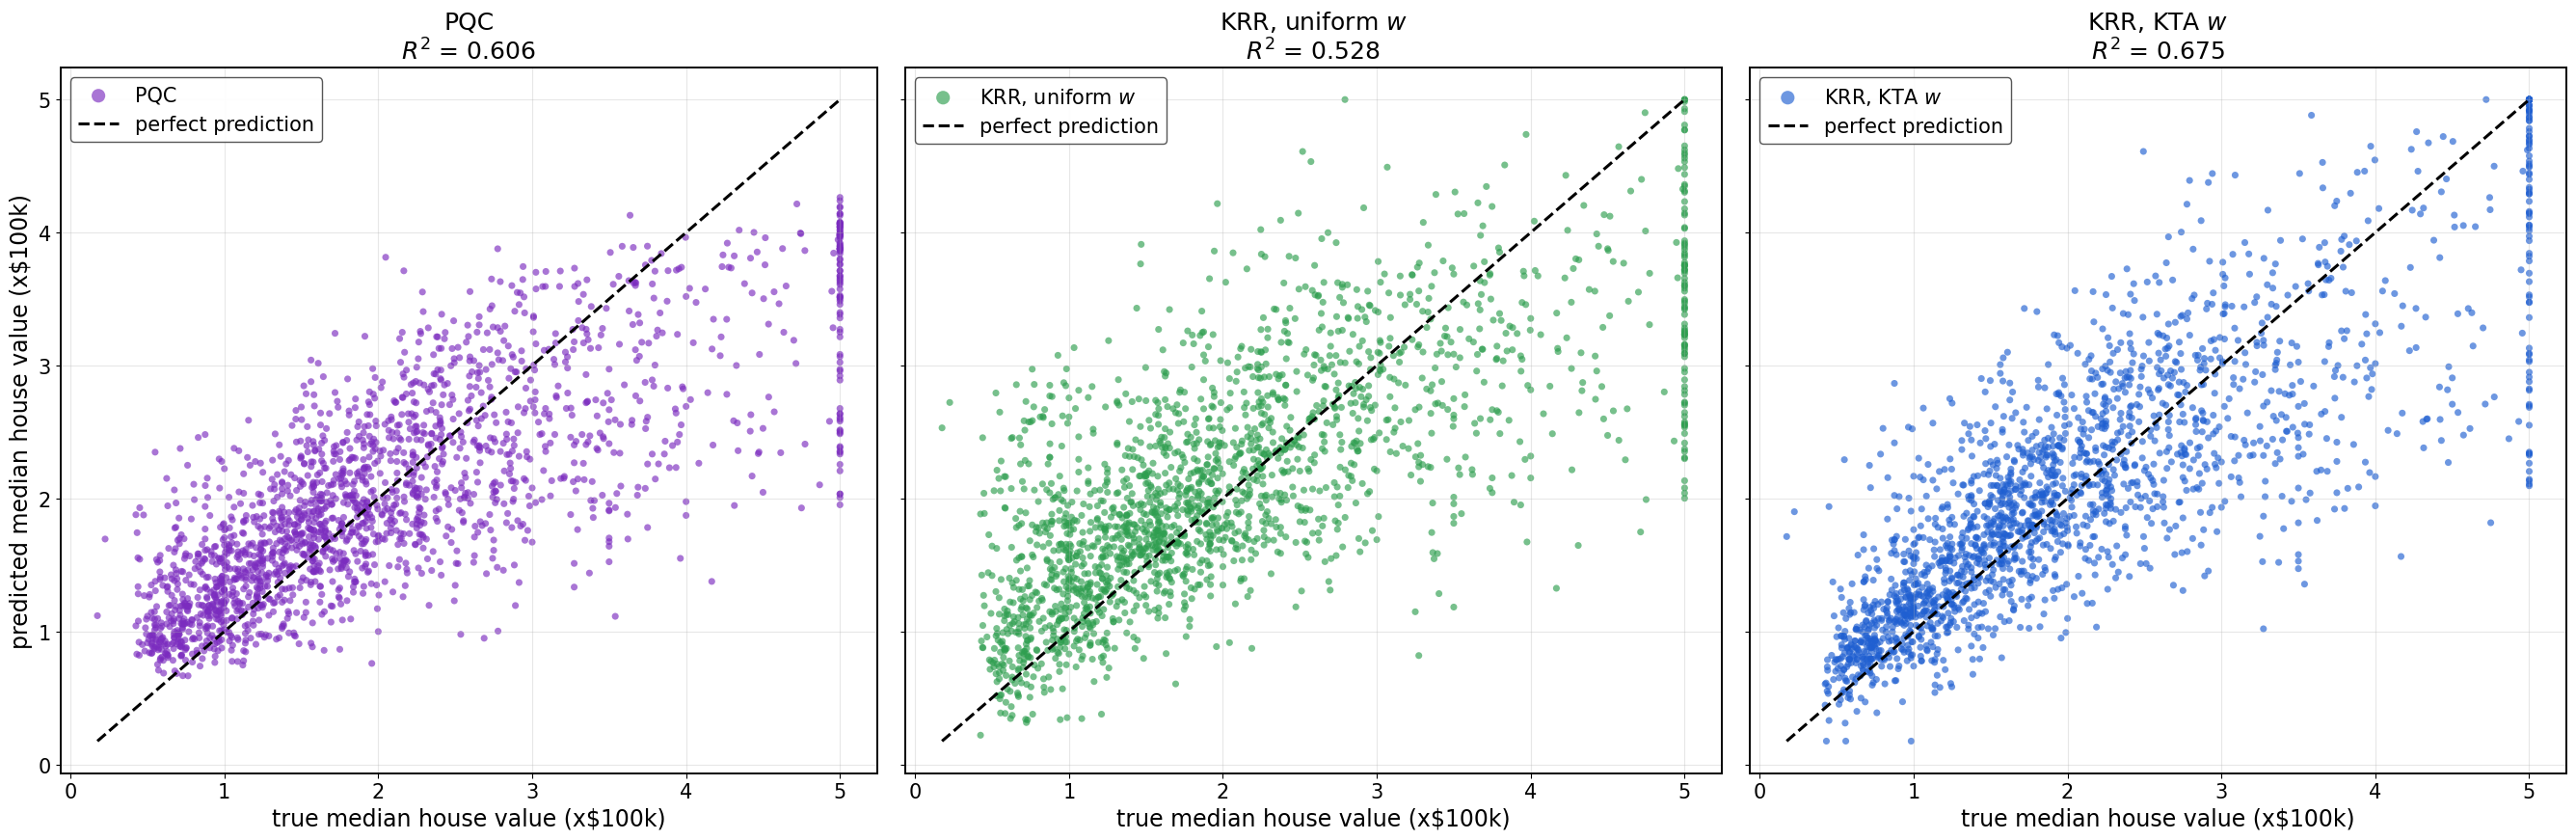

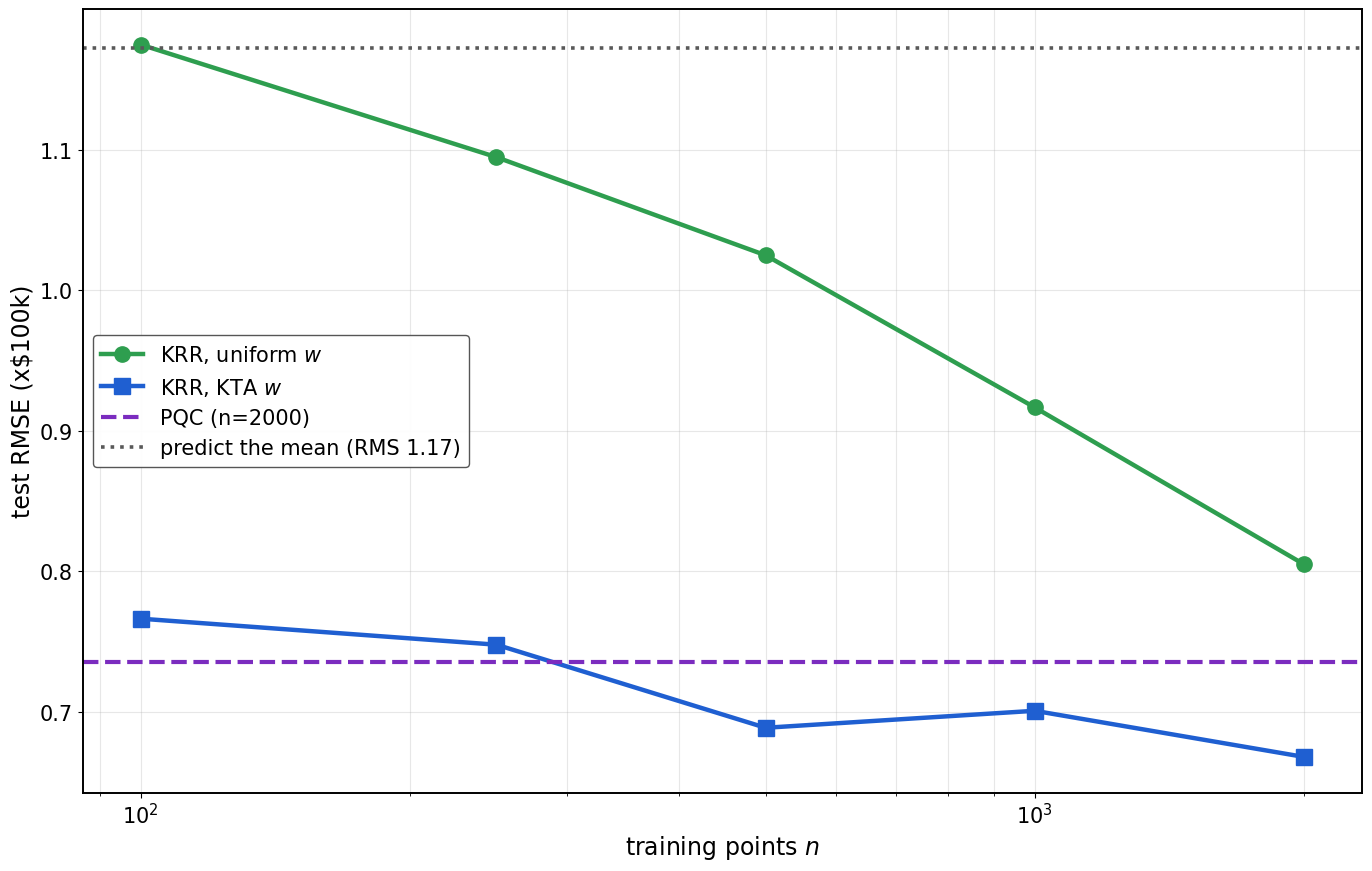

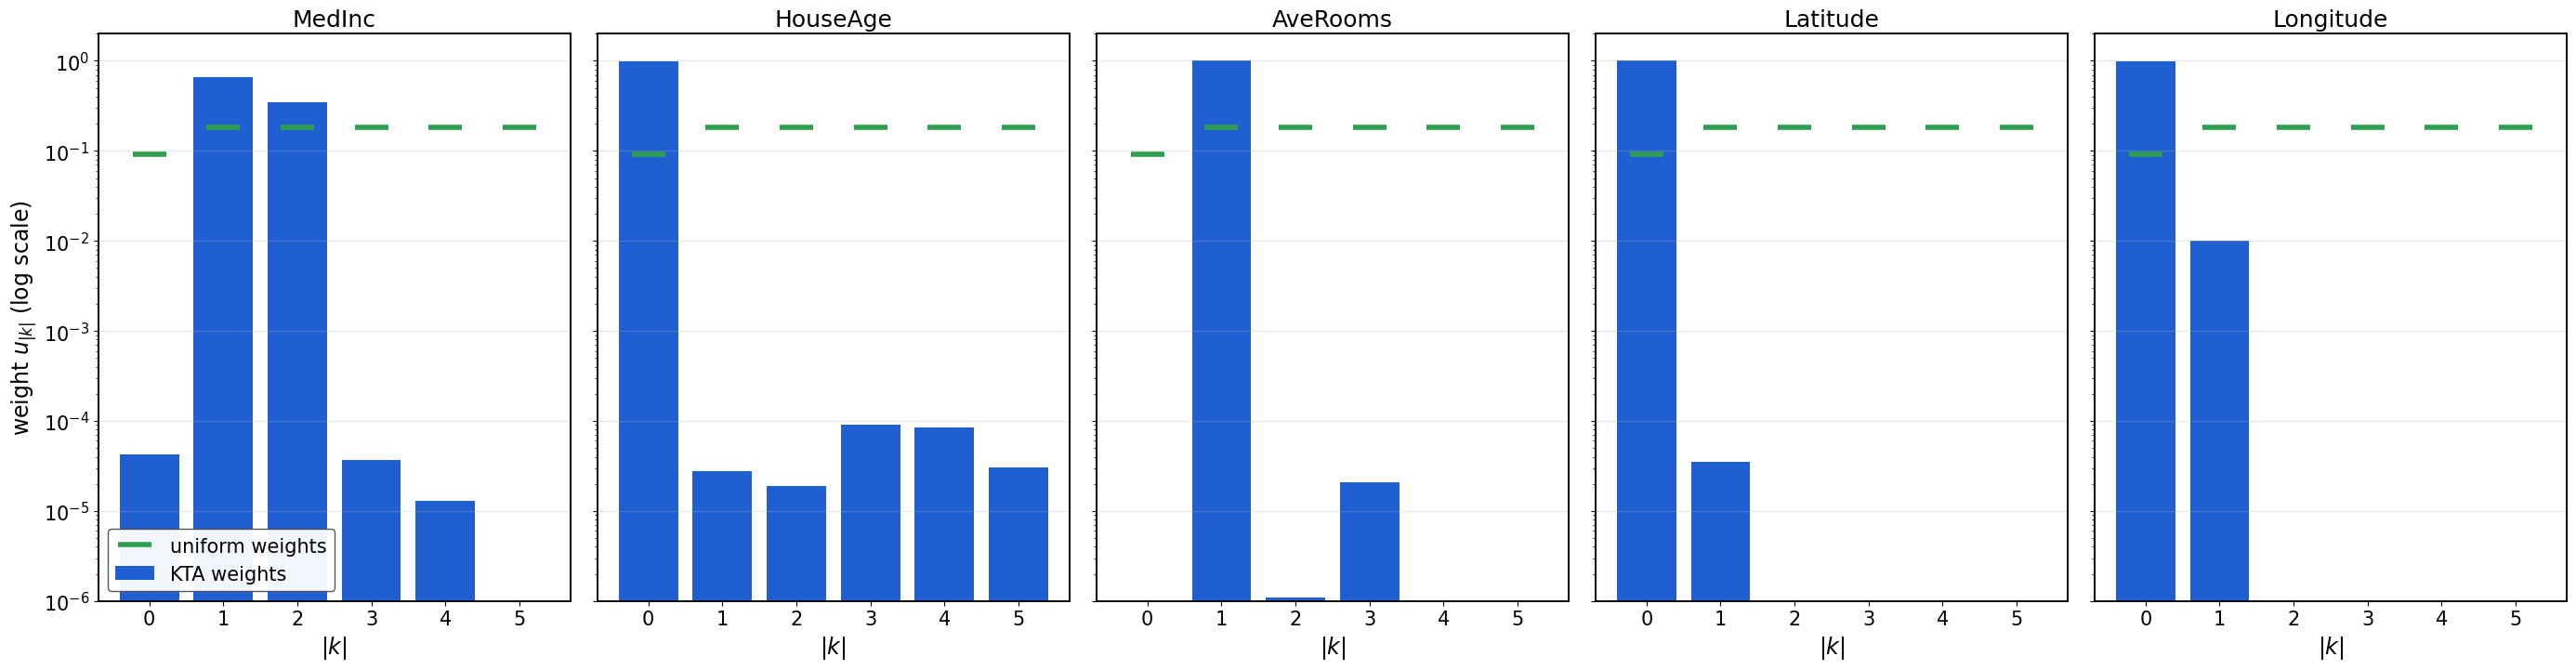

min / max predicted value over all models: 0.175 5.00001 (all >= 0: True )


In [ ]:
# R^2 = 1 - SSE / SST on the test set (invariant to the [-1, 1] rescaling); SST uses the test-set mean
r2 = lambda p, t: float(1 - np.sum((np.asarray(p) - t) ** 2) / np.sum((t - np.mean(t)) ** 2))
r2_from_rmse = lambda e: 1 - e ** 2 / np.var(yte)
print("test R^2:  PQC {:.3f} | KRR uniform {:.3f} | KRR KTA {:.3f} | KRR RBF {:.3f}".format(
      r2(pqc_pred_te, yte), r2(uni["pred"], yte), r2(kta["pred"], yte), r2(rbf["pred"], yte)))

# (a) predicted vs true on the test set (all values in median house value, target units)
fig, axs = plt.subplots(1, 3, figsize=(27, 9), sharex=True, sharey=True)
for ax, (name, pred, col) in zip(axs, [("PQC", pqc_pred_te, PQC_COLOR),
                                       ("KRR, uniform $w$", uni["pred"], KRR_UNI_COLOR),
                                       ("KRR, KTA $w$", kta["pred"], KRR_COLOR)]):
    ax.scatter(to_price(yte), to_price(pred), s=26, alpha=0.65, color=col, edgecolor="none", label=name)
    ax.plot([ymin, ymax], [ymin, ymax], "k--", lw=2.2, label="perfect prediction")
    ax.set_title(f"{name}\n$R^2$ = {r2(pred, yte):.3f}")
    ax.set_xlabel("true median house value (x\\$100k)")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left", markerscale=2)
axs[0].set_ylabel("predicted median house value (x\\$100k)")
fig.tight_layout(); fig.savefig(f"figures/{PREFIX}_fits.pdf", bbox_inches="tight"); fig.savefig(f"figures/{PREFIX}_fits.png", dpi=200, bbox_inches="tight")

# (b) learning curve
ns = [s[0] for s in sweep_res]
fig, ax = plt.subplots(figsize=(14, 9))
ax.plot(ns, [to_units(s[1]) for s in sweep_res], "o-", color=KRR_UNI_COLOR, lw=3.2, ms=11, label="KRR, uniform $w$")
ax.plot(ns, [to_units(s[2]) for s in sweep_res], "s-", color=KRR_COLOR, lw=3.2, ms=11, label="KRR, KTA $w$")
ax.axhline(to_units(pqc_res["test_rmse"]), color=PQC_COLOR, ls="--", lw=3, label=f"PQC (n={N_TRAIN})")
base_rmse = to_units(rmse(yte, ytr.mean()))
ax.axhline(base_rmse, color="0.35", ls=":", lw=2.6, label=f"predict the mean (RMS {base_rmse:.2f})")
ax.set_xscale("log"); ax.set_xlabel("training points $n$"); ax.set_ylabel("test RMSE (x\\$100k)")
ax.grid(alpha=0.3, which="both"); ax.legend(loc="best")
fig.tight_layout(); fig.savefig(f"figures/{PREFIX}_learning_curve.pdf", bbox_inches="tight"); fig.savefig(f"figures/{PREFIX}_learning_curve.png", dpi=200, bbox_inches="tight")

# (c) learned frequency weights per feature (KRR with KTA-learned w -> blue)
fig, axs = plt.subplots(1, D, figsize=(5.6 * D, 7.5), sharey=True)
ks_ = np.arange(L + 1)
for j, ax in enumerate(axs):
    u = np.exp(kta_logits[j]); u = u / u.sum()
    ax.bar(ks_, u, color=KRR_COLOR, label="KTA weights")
    ax.plot(ks_, [1/(2*L+1)] + [2/(2*L+1)] * L, "_", color=KRR_UNI_COLOR, ms=26, mew=4, label="uniform weights")
    ax.set_yscale("log"); ax.set_ylim(1e-6, 2)
    ax.set_title(FEATURES[j]); ax.set_xlabel("$|k|$")
    ax.grid(alpha=0.3, axis="y")
axs[0].set_ylabel("weight $u_{|k|}$ (log scale)")
axs[0].legend(loc="lower left")
fig.tight_layout(); fig.savefig(f"figures/{PREFIX}_kta_weights.pdf", bbox_inches="tight"); fig.savefig(f"figures/{PREFIX}_kta_weights.png", dpi=200, bbox_inches="tight")
plt.show()

allp = np.concatenate([to_price(pqc_pred_te), to_price(uni["pred"]), to_price(kta["pred"])])
print("min / max predicted value over all models:", allp.min(), allp.max(), "(all >= 0:", bool((allp >= 0).all()), ")")

with open(f"figures/{PREFIX}_results.json", "w") as f:
    json.dump(dict(config=dict(D=D, L=L, features=FEATURES, n_train=N_TRAIN, n_val=N_VAL, n_test=N_TEST,
                               n_kta=N_KTA, kta_restarts=KTA_RESTARTS, pqc_steps=PQC_STEPS, seed=SEED),
                   rmse_scaled={"pqc": pqc_res["test_rmse"], "krr_uniform": uni["test_rmse"],
                                "krr_kta": kta["test_rmse"], "krr_rbf": rbf["test_rmse"]},
                   rmse_target_units={"pqc": to_units(pqc_res["test_rmse"]), "krr_uniform": to_units(uni["test_rmse"]),
                                      "krr_kta": to_units(kta["test_rmse"]), "krr_rbf": to_units(rbf["test_rmse"])},
                   r2={"pqc": r2(pqc_pred_te, yte), "krr_uniform": r2(uni["pred"], yte), "krr_kta": r2(kta["pred"], yte), "krr_rbf": r2(rbf["pred"], yte)},
                   alignment={"uniform": uni["align"], "kta": kta["align"]},
                   sweep=sweep_res, kta_logits=kta_logits.tolist()), f, indent=2)